# LSTM 장단기 메모리 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week11/lstm/lab/lstm.ipynb)

셀 상태를 더하기로 이어 간다: $\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t$, $\quad \mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$.

- **파트 1**: numpy 로 LSTM 한 칸 → 손 계산, `nn.LSTMCell` 과 비교
- **파트 2**: 셰익스피어 글자 모델 `nn.RNN` vs `nn.LSTM` vs `nn.GRU`
- **파트 3**: 가중치 수 비교, 글 써 보기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 는 몇 분 걸린다.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. LSTM 한 칸

먼저 문 값을 직접 넣은 손 계산: $c_{t-1} = 2$, $f = 0.9$, $i = 0.5$, $\tilde{c} = 0.8$, $o = 0.7$ → $c_t = 2.2$, $h_t = 0.68$.

In [ ]:
def cell_update(c_prev, f, i, c_tilde, o):
    c = None  # TODO: new cell state
    h = None  # TODO: output
    return c, h

c, h = cell_update(2.0, 0.9, 0.5, 0.8, 0.7)
print("c =", round(c, 3), " h =", round(h, 3))

# Memory after 100 steps when the forget gate stays at f (nothing new written)
for f in [0.9, 0.99, 0.999]:
    print(f"f = {f}: {f ** 100 * 100:.3f}% left")

**예상 결과**

```
c = 2.2  h = 0.683
f = 0.9: 0.003% left
f = 0.99: 36.603% left
f = 0.999: 90.479% left
```

이제 문도 직접 계산한다. 네 묶음 가중치를 이어 붙인 큰 행렬 $W$ 하나에 $[\mathbf{x}, \mathbf{h}]$ 를 곱한 뒤 넷으로 나눈다. PyTorch 의 순서는 **i, f, c̃, o** (`nn.LSTMCell` 은 편향이 두 개: `bias_ih`, `bias_hh`).

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def lstm_step(x, h, c, W_ih, W_hh, b):
    z = W_ih @ x + W_hh @ h + b                          # 4 * hidden numbers
    zi, zf, zg, zo = np.split(z, 4)
    i, f, o = sigmoid(zi), sigmoid(zf), sigmoid(zo)
    c_tilde = np.tanh(zg)
    c = None  # TODO: new cell state
    h = None  # TODO: output
    return h, c

torch.manual_seed(0)
cell = nn.LSTMCell(3, 2)
W_ih, W_hh = cell.weight_ih.detach().numpy(), cell.weight_hh.detach().numpy()
b = (cell.bias_ih + cell.bias_hh).detach().numpy()
xs = np.array([[1.0, 0.0, -1.0], [0.5, 0.5, 0.5], [0.0, 1.0, 0.0]])

h, c = np.zeros(2), np.zeros(2)
ht, ct = torch.zeros(1, 2), torch.zeros(1, 2)
for x in xs:
    h, c = lstm_step(x, h, c, W_ih, W_hh, b)
    with torch.no_grad():
        ht, ct = cell(torch.tensor(x, dtype=torch.float32)[None], (ht, ct))
    print("numpy h:", h.round(4), "  torch h:", ht[0].numpy().round(4))

**예상 결과**

```
numpy h: [-0.1662 -0.0744]   torch h: [-0.1662 -0.0744]
numpy h: [-3.096e-01  2.000e-04]   torch h: [-3.096e-01  2.000e-04]
numpy h: [-0.3939  0.0212]   torch h: [-0.3939  0.0212]
```

## 파트 2. RNN vs LSTM vs GRU

지난 시간의 셰익스피어 글자 모델. `nn.RNN` 자리만 바꿔 끼운다. 학습은 앞 90% 글, 검증 손실은 뒤 10% 글로 잰다.

In [ ]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/shakespeare.txt"):
    import urllib.request; urllib.request.urlretrieve(url, "data/shakespeare.txt")
text = open("data/shakespeare.txt").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text])
cut = int(len(data) * 0.9)
train_data, val_data = data[:cut], data[cut:]
print(len(train_data), "train characters,", len(val_data), "validation characters,", len(chars), "distinct")

**예상 결과**

```
1003854 train characters, 111540 validation characters, 65 distinct
```

In [ ]:
class CharModel(nn.Module):
    def __init__(self, kind, vocab, hidden=128):
        super().__init__()
        self.kind = kind
        self.emb = nn.Embedding(vocab, hidden)
        layer = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = layer(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, x, state=None):
        o, state = self.rnn(self.emb(x), state)          # LSTM state = (h, c), RNN/GRU state = h
        return self.out(o), state

def get_batch(data, seq=64, batch=64, gen=None):
    ix = torch.randint(0, len(data) - seq - 1, (batch,), generator=gen)
    x = torch.stack([data[i:i + seq] for i in ix])
    y = torch.stack([data[i + 1:i + seq + 1] for i in ix])
    return x, y

def train(kind, train_data, vocab, steps=1000):
    torch.manual_seed(0)
    model = None  # TODO: build the model of this kind
    opt = torch.optim.Adam(model.parameters(), 3e-3); gen = torch.Generator().manual_seed(0)
    losses = []
    for step in range(steps):
        x, y = get_batch(train_data, gen=gen)
        logits, _ = model(x)
        loss = nn.functional.cross_entropy(logits.reshape(-1, vocab), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        losses.append(loss.item())
    return model, losses

def val_loss(model, val_data, vocab):
    x, y = get_batch(val_data, batch=200, gen=torch.Generator().manual_seed(1))
    with torch.no_grad():
        logits, _ = model(x)
    return nn.functional.cross_entropy(logits.reshape(-1, vocab), y.reshape(-1)).item()

models = {}
for kind in ["rnn", "lstm", "gru"]:
    model, losses = train(kind, train_data, len(chars))
    models[kind] = model
    print(f"{kind:5s} validation loss {val_loss(model, val_data, len(chars)):.3f}")
    plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"), label=kind)
plt.xlabel("step"); plt.ylabel("training loss (50-step average)"); plt.legend(); plt.show()

**예상 결과**

```
rnn   validation loss 1.774
lstm  validation loss 1.696
gru   validation loss 1.701
```

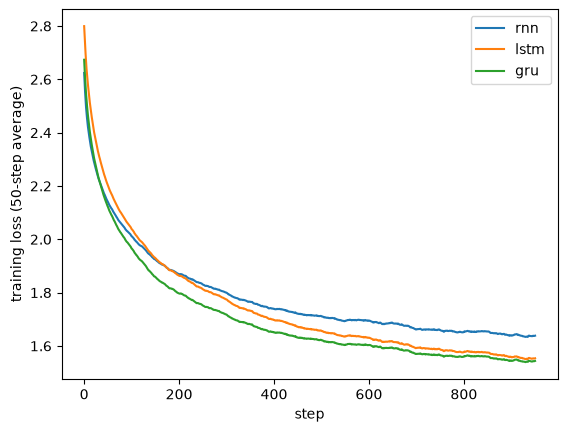

## 파트 3. 가중치 수 · 글 써 보기

LSTM 은 묶음 4개, GRU 는 3개, RNN 은 1개. 슬라이드 문제 3 은 편향을 하나로 셌지만 PyTorch 는 편향이 두 개 (`bias_ih`, `bias_hh`) 라 조금 더 많다.

In [ ]:
def count_params(module):
    return None  # TODO: total number of weights

for kind in ["rnn", "lstm", "gru"]:
    print(f"{kind:5s} recurrent layer: {count_params(models[kind].rnn):7,d} weights")
print("slide problem 3 (input 100, hidden 128):", count_params(nn.LSTM(100, 128)))

**예상 결과**

```
rnn   recurrent layer:  33,024 weights
lstm  recurrent layer: 132,096 weights
gru   recurrent layer:  99,072 weights
slide problem 3 (input 100, hidden 128): 117760
```

In [ ]:
def generate(model, start, stoi, chars, n=300, temperature=0.8, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor([[stoi[c] for c in start]]); out = start
    with torch.no_grad():
        logits, state = model(x)
        for _ in range(n):
            p = torch.softmax(logits[0, -1] / temperature, dim=0)
            c = torch.multinomial(p, 1, generator=g).item()
            out += chars[c]
            logits, state = model(torch.tensor([[c]]), state)
    return out

for kind in ["rnn", "lstm"]:
    print(f"--- {kind} ---"); print(generate(models[kind], "ROMEO:", stoi, chars, 250)); print()

**예상 결과**

```
--- rnn ---
ROMEO:
Why more the preverelouch nextand,
Now gelse than of thy hath were my strenge she hast sainted the peaces or we percances is discorded; my father we would for me himent,
By the contranger,
I shall wast to faith and look,--
not say, in come me being 

--- lstm ---
ROMEO:
Threm fair sween? for Hear expare, but gelse, great upon his tweeter hath home to ever of the contents,
He rewelped and send with a none hands
How speak to dain wiitentory,
Whence this well dene. So I fearful him mink my honours,
This come me beone 
```

**확인 질문**
1. 파트 1 에서 잊는 문이 0.99 일 때와 0.9 일 때 100걸음 뒤 남는 기억은 몇 배 차이인가?
2. 파트 2 에서 세 모델의 검증 손실 순서는? 가중치 수 (파트 3) 를 생각하면 공정한 비교일까?
3. LSTM 에서 `state` 는 왜 `(h, c)` 두 개인가? 다음 칸에 둘 다 넘겨야 하는 이유는?
4. (도전) `get_batch` 의 `seq` 를 128 로 늘리면 RNN 과 LSTM 의 차이가 커지나?

데이터 출처: Tiny Shakespeare, Andrej Karpathy char-rnn (2015).